In [47]:
import torch
import numpy
from matplotlib import pyplot

import importlib
import velocity_model
import estimate_velocity
importlib.reload(velocity_model)
importlib.reload(estimate_velocity)

L = 5e6
Growthrate = torch.tensor([1/(20*60)], dtype=torch.double)
v0 = 1e3
Tr = L/(2*v0)
origins = torch.tensor([2e6, 4e6], dtype=torch.int32)
delay = torch.tensor([360.0, 0.0], dtype=torch.double)
h_tgrid = torch.linspace(0, 0.6*Tr, steps=11, dtype=torch.double)
g_xranges_l = torch.tensor([1e6, 4.5e6], dtype=torch.int32)
g_xranges_u = torch.tensor([1.1e6, 4.6e6], dtype=torch.int32)

mtrue = velocity_model.VelocityModel(L, True, origins, h_tgrid, g_xranges_l, g_xranges_u)
mtrue.growthrate = Growthrate
mtrue.delay = delay
mtrue.v0 = torch.tensor([v0], dtype=torch.double)
mtrue.h_log_raw = torch.log(torch.tensor([1, 1, 1.5, 2, 1.5, 1, 0.5, 0.1, 0.5, 1, 1], dtype=torch.double))
mtrue.g_log = torch.log(torch.tensor([10, 0.1], dtype=torch.double))

coverage = 1e3
x = torch.linspace(0, L, steps=1000)
y_obs = torch.poisson(mtrue.P(x) * coverage).detach().numpy()
s_obs = numpy.sqrt(y_obs)

In [48]:
h_tgrid_dense = torch.linspace(0, 0.6*Tr, steps=100, dtype=torch.double)
m = velocity_model.VelocityModel(L, True, origins, h_tgrid_dense, g_xranges_l, g_xranges_u)
m.growthrate = Growthrate
m.h_sigma = torch.tensor([1], dtype=torch.double)
m.h_timescale = torch.nn.Parameter(torch.tensor([1e2], dtype=torch.double))

#torch.autograd.set_detect_anomaly(True)
l = velocity_model.VelocityModelLoss(x, torch.tensor(y_obs), torch.tensor(s_obs), m)
fit = estimate_velocity.FitVelocityModel(m, l)
fit.optimize()

In [49]:
print(fit.model.delay)
print(fit.loss())
print(fit.model.penalty())

Parameter containing:
tensor([339.7009,  29.8717], dtype=torch.float64, requires_grad=True)
tensor(490.6540, dtype=torch.float64, grad_fn=<AddBackward0>)
tensor(2.9865, dtype=torch.float64, grad_fn=<MulBackward0>)


(0.0, 1.1)

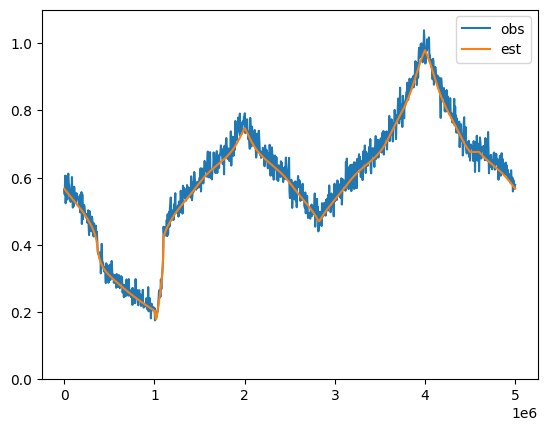

In [50]:
p = m.P(x).detach().numpy()
ptrue = mtrue.P(x).detach().numpy()
pyplot.plot(x, (numpy.mean(ptrue) * y_obs / numpy.mean(y_obs)), label="obs")
#pyplot.plot(x, ptrue, label="true")
pyplot.plot(x, p, label="est")
#pyplot.plot(x, ptrue, label="true")
pyplot.legend()
pyplot.ylim([0.0, 1.1])

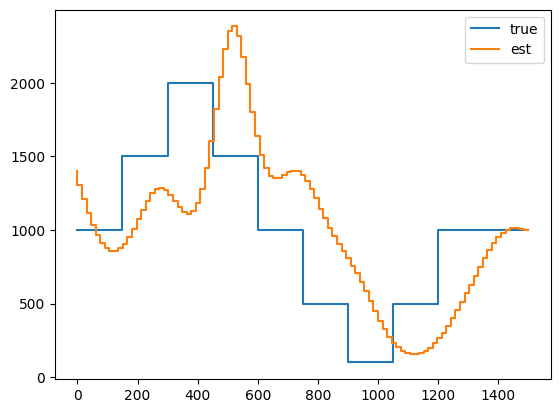

In [51]:
pyplot.step(mtrue.h_tgrid, (mtrue.v0 * torch.exp(mtrue.h_log("canonical"))).detach().numpy(), label="true")
pyplot.step(m.h_tgrid, (m.v0 * torch.exp(m.h_log("canonical"))).detach().numpy(), label="est")
pyplot.legend()